# Week 8 Coding

**C1** checks the hand results of the problem set with the FFT. **C2** reads the heart rate from the measured pulse signal of the lecture. **C3** (optional) builds a simplified guitar tuner.

**Predict first.** Before running any check cell, write down on paper what the output will be.

**How to work in this notebook.** Execute the cells in order with Shift+Enter. Each task has a cell with gaps marked `...`: fill them, run the cell, then execute the check cell below it. A passing check prints a confirmation; a failing one raises an `AssertionError`.

In [20]:
import numpy as np
import matplotlib.pyplot as plt

## C1: The hand results, checked (P1, P2, P3, P6, P11)

Both functions use the convention of this course: `np.fft.fft(x)` returns $X[k] = \sum_{n=0}^{N-1} x[n]\,e^{-j2\pi kn/N}$, and `np.fft.ifft(X)` returns $x[n] = \frac1N \sum_{k=0}^{N-1} X[k]\,e^{j2\pi kn/N}$. Enter the results computed by hand; complex numbers are written as `1 - 2j`.

In [21]:
X_P1 = np.array([4, 2, 0, 2])                 # P1: DFS coefficients of one period {2, 1, 0, 1}
X_P2 = np.array([3, 1-2j, -1, 1+2j])                 # P2: DFT of {1, 2, 0, 0}
x_P3 = 1+np.sin(np.pi/2 * n)                             # P3: the signal, as an expression in n
n = np.arange(8)
mag_P6 = np.array([0,0,4,0,8,0,4,0])               # P6: |X[0]|, ..., |X[7]| of cos(pi n/2) + cos(pi n)
zeros_P11 = [2,4,6]                      # P11: the k with X[k] = 0

In [22]:
assert np.allclose(np.fft.fft([2, 1, 0, 1]), X_P1), "P1"
assert np.allclose(np.fft.fft([1, 2, 0, 0]), X_P2), "P2"
X3 = np.zeros(8, complex); X3[0], X3[2], X3[6] = 8, -4j, 4j
assert np.allclose(np.fft.ifft(X3), x_P3), "P3"
assert np.allclose(np.abs(np.fft.fft(np.cos(np.pi * n / 2) + np.cos(np.pi * n))), mag_P6), "P6"
X11 = np.fft.fft([1, 1, 1, 1, 0, 0, 0, 0])
assert list(np.flatnonzero(np.abs(X11) < 1e-12)) == list(zeros_P11), "P11"
print("C1 passed: the hand results of P1, P2, P3, P6 and P11 agree with the FFT.")

C1 passed: the hand results of P1, P2, P3, P6 and P11 agree with the FFT.


## C2: The heart rate from a measured pulse signal (P4, P7, in-class)

The file `data/bidmc_03_pleth_60s.csv` contains the first $60$ s of the photoplethysmogram of the lecture: subject 03 of the BIDMC PPG and Respiration Dataset (PhysioNet, Open Data Commons Attribution License), sampled at $f_s = 125$ Hz. The bedside monitor displayed between $75$ and $78$ beats per minute.

**a)** Complete `ppg_spectrum`, which returns the frequencies $f_k = k f_s/N$ and the magnitudes $\lvert X[k]\rvert$ for $k = 0, \dots, N/2$. Use `np.fft.rfft`, which returns exactly these $N/2 + 1$ coefficients of a real signal.

**b)** Complete `heart_rate`: the frequency of the largest magnitude between $0.7$ Hz and $3$ Hz, which excludes $k = 0$, converted to beats per minute. Before running, predict the three heart rates from the lecture.

In [23]:
fs_ppg = 125
ppg = np.loadtxt("data/bidmc_03_pleth_60s.csv", delimiter=",", skiprows=1)[:, 1]

def ppg_spectrum(x):
    """Frequencies f_k = k fs / N and magnitudes |X[k]|, k = 0..N/2."""
    X_abs = np.abs(np.fft.rfft(x))                                                        # your code: the magnitudes
    f_k = np.arange(len(X_abs)) * fs_ppg/len(x)                                                        # your code: the frequencies of the bins
    return f_k, X_abs

def heart_rate(x):
    f, X = ppg_spectrum(x)
    band = (f > 0.7) & (f < 3)
    f_peak = f[band][np.argmax(X[band])]                                                   # your code: the frequency of the largest X within the band
    return 60 * f_peak

for T in (10, 30, 60):
    print(f"T = {T:2d} s: bin spacing {60 * fs_ppg / (T * fs_ppg):.0f} bpm, heart rate {heart_rate(ppg[:T * fs_ppg]):.0f} bpm")

T = 10 s: bin spacing 6 bpm, heart rate 78 bpm
T = 30 s: bin spacing 2 bpm, heart rate 76 bpm
T = 60 s: bin spacing 1 bpm, heart rate 76 bpm


In [24]:
f10, X10 = ppg_spectrum(ppg[:1250])
assert len(f10) == 626 and np.isclose(f10[1], 0.1)                 # N/2 + 1 bins, 0.1 Hz apart
assert np.isclose(X10[0], 1250 * ppg[:1250].mean())                # X[0] = N times the mean
assert [round(heart_rate(ppg[:T * 125])) for T in (10, 30, 60)] == [78, 76, 76]
f60, X60 = ppg_spectrum(ppg)
low = (f60 > 0.1) & (f60 < 0.6)
assert abs(f60[low][np.argmax(X60[low])] - 0.283) < 0.01            # the breathing, 17 per minute
print("C2 passed: 78, 76 and 76 bpm, as in the lecture; X[0] is N times the mean.")

C2 passed: 78, 76 and 76 bpm, as in the lecture; X[0] is N times the mean.


**c)** Run the plot cell. The dashed lines mark integer multiples of the heart rate found for $60$ s. Which peaks lie at integer multiples of the heart rate, and which peak near $0.3$ Hz does not?

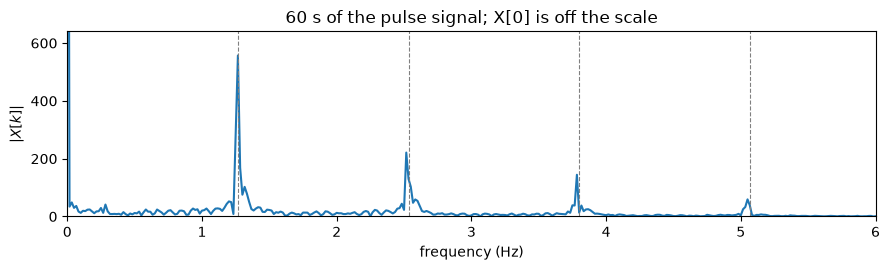

In [25]:
f60, X60 = ppg_spectrum(ppg)
f_hr = heart_rate(ppg) / 60
plt.figure(figsize=(9, 2.8))
plt.plot(f60, X60); plt.xlim(0, 6); plt.ylim(0, 1.15 * X60[(f60 > 0.7)].max())
for m in range(1, 5):
    plt.axvline(m * f_hr, ls="--", color="gray", lw=0.8)
plt.xlabel("frequency (Hz)"); plt.ylabel("$|X[k]|$"); plt.title("60 s of the pulse signal; X[0] is off the scale")
plt.tight_layout()

## C3 (optional): A Simplified Guitar Tuner

A tuner records a plucked string for a fraction of a second, finds its fundamental frequency $f_0$ and reports how far it lies from the target note. This task builds one in four steps, from the DFT of Week 8: **a)** the spectrum in hertz, **b)** the fundamental, **c)** the bin spacing in cents, **d)** a precise estimate by zero-padding. **e)** is an experiment on what zero-padding does not achieve.

Deviations between musical frequencies are measured in **cents**: one semitone is 100 cents, and the deviation of $f$ from a reference $f_\text{ref}$ is
$$c = 1200 \log_2 \frac{f}{f_\text{ref}}.$$
A tuner should be accurate to about one cent.

### The recordings

The six strings of a guitar in standard tuning are recorded for $T = 0.5$ s at $f_s = 8000$ Hz. Each recording is synthesized as six harmonics with decaying amplitudes and a little noise. As on many real low strings, the second harmonic is stronger than the fundamental. Every string is slightly out of tune; the deviations are hidden in `_detune` and used only by the check cells.

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio

fs = 8000
STRINGS = {"E2": 82.41, "A2": 110.00, "D3": 146.83, "G3": 196.00, "B3": 246.94, "E4": 329.63}   # target f0 in Hz

def pluck(f0, T=0.5, seed=0, amps=(0.5, 1, 0.7, 0.5, 0.3, 0.2)):
    """Six harmonics of f0 with decaying amplitudes, plus a little white noise."""
    t = np.arange(int(round(T * fs))) / fs
    x = sum(a * np.exp(-(1 + m)*t) * np.cos(2*np.pi*(m + 1)*f0*t + 0.7*m) for m, a in enumerate(amps))
    return x + 0.05 * np.random.default_rng(seed).standard_normal(len(t))

_detune = {"E2": -10, "A2": 25, "D3": -40, "G3": 3, "B3": -7, "E4": 15}   # cents, hidden from the tuner
recordings = {s: pluck(f * 2**(_detune[s]/1200), seed=i) for i, (s, f) in enumerate(STRINGS.items())}

def cents(f, f_ref):
    return 1200 * np.log2(f / f_ref)

Audio(np.tile(recordings["E2"], 3), rate=fs)

### a) The spectrum in hertz

Complete `spectrum`, which returns the frequencies $f_k = k f_s/n$ and the magnitudes $\lvert X[k]\rvert$ for $k = 0, \dots, n/2$, where $n$ is the length of the DFT. Use `np.fft.rfft(x, n)`; when `n` is larger than the signal, the signal is first extended with zeros (used in d).

Before running the check cell, compute the bin spacing for $T = 0.5$ s, and predict the frequency of the largest peak of the low E string, whose target is $82.41$ Hz.

In [37]:
def spectrum(x, n=None):
    """Frequencies f_k = k fs / n and magnitudes |X[k]| of the n-point DFT, k = 0..n/2."""
    n = n or len(x)
    X = np.abs(np.fft.rfft(x,n))                                                        # your code: the magnitudes
    f = np.arange(len(X)) * fs / n                                                      # your code: the frequencies of the bins
    return f, X

f, X = spectrum(recordings["E2"])
print("bin spacing:", f[1], "Hz;  largest peak at", f[np.argmax(X)], "Hz")

bin spacing: 2.0 Hz;  largest peak at 164.0 Hz


a) passed: bins 2 Hz apart; the largest peak is at 164 Hz, the second harmonic of the low E string.


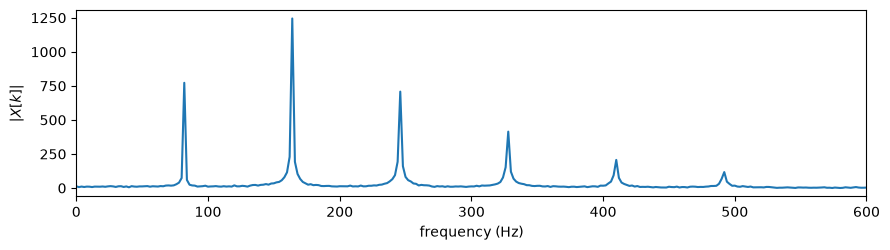

In [38]:
assert np.isclose(f[1], 2.0) and len(f) == 2001                    # Delta f = fs / N = 1 / T
assert np.isclose(f[np.argmax(X)], 164.0)                          # the second harmonic, not f0
plt.figure(figsize=(9, 2.6)); plt.plot(f, X); plt.xlim(0, 600)
plt.xlabel("frequency (Hz)"); plt.ylabel("$|X[k]|$"); plt.tight_layout()
print("a) passed: bins 2 Hz apart; the largest peak is at 164 Hz, the second harmonic of the low E string.")

### b) The fundamental

A tuner that reports the largest peak reads the low E string one octave too high. The fundamental is the **lowest** of the harmonics: the lowest local maximum of $\lvert X[k]\rvert$ that exceeds a fraction `rel` of the largest one.

Complete `fundamental`. The local maxima are given.

In [34]:
def fundamental(f, X, rel=0.2):
    """Frequency of the lowest local maximum of X that exceeds rel times the largest value."""
    k = np.arange(1, len(X) - 1)
    is_max = (X[k] > X[k - 1]) & (X[k] >= X[k + 1])
    strong = X[k] > rel * X.max()                                                   # your code: the condition X[k] > rel * max(X)
    return f[k[is_max & strong][0]]

for s, x in recordings.items():
    print(s, fundamental(*spectrum(x)), "Hz")

E2 82.0 Hz
A2 112.0 Hz
D3 144.0 Hz
G3 196.0 Hz
B3 246.0 Hz
E4 332.0 Hz


In [35]:
coarse = {s: fundamental(*spectrum(x)) for s, x in recordings.items()}
for s, fc in coarse.items():
    true_f0 = STRINGS[s] * 2**(_detune[s]/1200)
    assert abs(fc - true_f0) <= 1.0                                 # within half a bin
print("b) passed: the fundamental of every string is found to within half a bin (1 Hz).")

b) passed: the fundamental of every string is found to within half a bin (1 Hz).


### c) The bin spacing in cents

The estimate of b) is a bin frequency, so it is accurate only to about half the bin spacing $\Delta f = 1/T$.

Compute, in cents, the bin spacing at the low E string, $\Delta f$ above $82.41$ Hz. Then compute the signal length $T$ for which one bin is one cent at $82.41$ Hz. Before running, estimate both.

In [40]:
c_bin = cents(82.41 + 2.0, 82.41)                                                        # your code: cents(82.41 + Delta f, 82.41) with Delta f = 2 Hz
T_1cent = 1 / (82.41 * (2**(1/1200) - 1))                                              # your code: the T with 1/T = 82.41 (2^(1/1200) - 1)
print(f"one bin = {c_bin:.1f} cents;  one cent per bin needs T = {T_1cent:.1f} s")

one bin = 41.5 cents;  one cent per bin needs T = 21.0 s


In [41]:
assert abs(c_bin - 41.5) < 0.1
assert abs(T_1cent - 21.0) < 0.1
print("c) passed: one bin is 41.5 cents at low E; a bin of one cent would require a signal of 21 s.")

c) passed: one bin is 41.5 cents at low E; a bin of one cent would require a signal of 21 s.


### d) A precise estimate by zero-padding

The DFT of $N$ samples consists of samples of the DTFT $X(\Omega)$ at the $N$ frequencies $\Omega_k = 2\pi k/N$ (Video 3). If the signal is extended with zeros to length $n > N$, the DTFT is unchanged, since the added samples are zero, and the DFT of length $n$ samples the **same** DTFT on a finer grid, with spacing $f_s/n$. The maximum of a single peak can therefore be located much more precisely than the bin spacing $f_s/N$.

Complete `tuner`: take the coarse estimate of b), compute the zero-padded spectrum with $n = 2^{18}$ (grid spacing $0.03$ Hz), and return the frequency of its maximum within one bin spacing $f_s/N$ of the coarse estimate. Then report the nearest string and the deviation in cents.

In [43]:
def tuner(x, n=2**18):
    f_coarse = fundamental(*spectrum(x))
    df = fs / len(x)                                               # the bin spacing of the signal
    fz, Z = spectrum(x,n)                                                    # your code: the zero-padded spectrum
    band = (fz > f_coarse - df) & (fz < f_coarse + df)
    f0 = fz[band][np.argmax(Z[band])]                                                       # your code: the frequency of the maximum of Z within the band
    string = min(STRINGS, key=lambda s: abs(cents(f0, STRINGS[s])))
    return string, f0, cents(f0, STRINGS[string])

for s, x in recordings.items():
    string, f0, c = tuner(x)
    print(f"{string}: f0 = {f0:7.2f} Hz, {c:+6.1f} cents")

E2: f0 =   81.94 Hz,   -9.9 cents
A2: f0 =  111.60 Hz,  +25.0 cents
D3: f0 =  143.46 Hz,  -40.2 cents
G3: f0 =  196.35 Hz,   +3.1 cents
B3: f0 =  245.94 Hz,   -7.0 cents
E4: f0 =  332.49 Hz,  +15.0 cents


In [44]:
for s, x in recordings.items():
    string, f0, c = tuner(x)
    assert string == s and abs(c - _detune[s]) < 0.5                # within half a cent
print("d) passed: every string is identified, and its deviation is measured to within half a cent from 0.5 s.")

d) passed: every string is identified, and its deviation is measured to within half a cent from 0.5 s.


### e) What zero-padding does not achieve

Zero-padding locates the maximum of **one** peak precisely. Run the cell: it computes the zero-padded spectrum of two tones at $440$ Hz and $441$ Hz, recorded for $T = 0.5$ s and for $T = 2$ s.

1. For which signal length are the two tones visible as two peaks? Relate the answer to $\Delta f = 1/T$.
2. Why does zero-padding not help in the first case, although it helped in d)?

1. Only for $T = 2$ s, with $\Delta f = 0.5$ Hz, smaller than the separation of $1$ Hz. For $T = 0.5$ s, $\Delta f = 2$ Hz, and the zero-padded spectrum shows a single peak near $440.5$ Hz.
2. Zero-padding samples the DTFT of the signal more finely but does not change it. For $T = 0.5$ s, the DTFT itself contains one wide peak, since the two tones lie within its width of about $1/T$; a finer grid only draws this single peak more smoothly. Separating two tones requires a longer signal; locating one isolated peak does not.

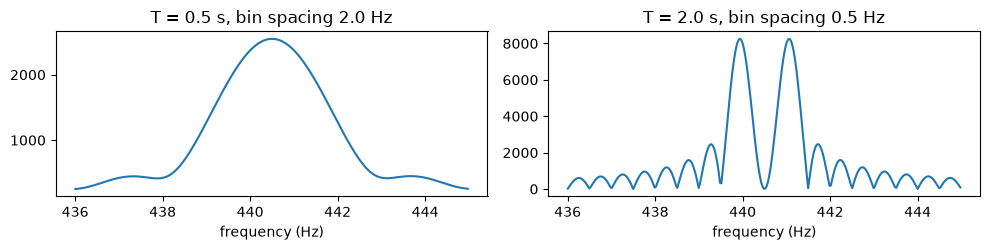

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(10, 2.6))
for ax, T in zip(axes, (0.5, 2.0)):
    t = np.arange(int(T * fs)) / fs
    x2 = np.cos(2*np.pi*440*t) + np.cos(2*np.pi*441*t)
    fz, Z = spectrum(x2, 2**18)
    band = (fz > 436) & (fz < 445)
    ax.plot(fz[band], Z[band]); ax.set_title(f"T = {T} s, bin spacing {1/T} Hz")
    ax.set_xlabel("frequency (Hz)")
plt.tight_layout()